# Dataset Audit Notebook

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from pathlib import Path

# Define the path to the Excel file
file_path = Path(
    "../data/raw/SY 2023-2024 School Level Data on Official Enrollment 13.xlsx"
)

# Load the workbook and print the sheet names
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

['DB', 'Zero Enrollment', 'Sheet2']


In [2]:
# Preview the first 10 rows of each worksheet
for sheet_name in excel_file.sheet_names:

    df_preview = pd.read_excel(
        file_path,
        sheet_name=sheet_name,
        header=None,
        nrows=10
    )

    print(f"\n{'=' * 60}")
    print(f"WORKSHEET: {sheet_name}")
    print(f"{'=' * 60}")

    print(df_preview.to_string(index=False, header=False))


WORKSHEET: DB
SCHOOL LEVEL DATA ON OFFICIAL ENROLLMENT IN ALL GRADE LEVELS          NaN       NaN            NaN                       NaN                                      NaN          NaN          NaN                  NaN               NaN    NaN                      NaN                    NaN          NaN          NaN      NaN     NaN       NaN     NaN       NaN     NaN       NaN     NaN       NaN     NaN       NaN     NaN       NaN                  NaN            NaN     NaN       NaN     NaN       NaN     NaN       NaN      NaN        NaN                   NaN           NaN                 NaN                   NaN                   NaN                     NaN                NaN                  NaN               NaN                 NaN               NaN                 NaN          NaN            NaN             NaN               NaN                    NaN             NaN                 NaN                   NaN                   NaN                     NaN                Na

## Structural Profiling

In [3]:
# Inspect the main DB worksheet
df = pd.read_excel(
    file_path,
    sheet_name="DB",
    header=4
)

print("Preview of the loaded dataset:")
print(df.head())
print(df.tail())

Preview of the loaded dataset:
     Region      Division   District  BEIS School ID  \
0  Region I  Ilocos Norte  Bacarra I          100001   
1  Region I  Ilocos Norte  Bacarra I          100002   
2  Region I  Ilocos Norte  Bacarra I          100003   
3  Region I  Ilocos Norte  Bacarra I          100004   
4  Region I  Ilocos Norte  Bacarra I          100005   

                 School Name                            Street Address  \
0         Apaleng-Libtong ES  Brgy. 21, Libtong, Bacarra, Ilocos Norte   
1                Bacarra CES                                Santa Rita   
2                   Buyon ES                                      NONE   
3  Ganagan Elementary School         #37 Ganagan,Bacarra, Ilocos Norte   
4                 Macupit ES                                   Macupit   

       Province Municipality Legislative District           Barangay  ...  \
0  ILOCOS NORTE      BACARRA         1st District            LIBTONG  ...   
1  ILOCOS NORTE      BACARRA     

In [4]:
# Inspect dataset dimensions and column names
print("Dataset dimensions:", df.shape)

rows, columns = df.shape

print("Number of records:", rows)
print("Number of columns:", columns)
print("Total records:", len(df))
print("Total columns:", len(df.columns))

# Inspect the dataset summary
df.info()

Dataset dimensions: (60167, 72)
Number of records: 60167
Number of columns: 72
Total records: 60167
Total columns: 72
<class 'pandas.DataFrame'>
RangeIndex: 60167 entries, 0 to 60166
Data columns (total 72 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Region                    60167 non-null  str  
 1   Division                  60167 non-null  str  
 2   District                  60167 non-null  str  
 3   BEIS School ID            60167 non-null  int64
 4   School Name               60167 non-null  str  
 5   Street Address            58485 non-null  str  
 6   Province                  60167 non-null  str  
 7   Municipality              60167 non-null  str  
 8   Legislative District      60167 non-null  str  
 9   Barangay                  60097 non-null  str  
 10  Sector                    60167 non-null  str  
 11  School Subclassification  60167 non-null  str  
 12  School Type               60167 non-n

In [5]:
# Enumarate column names
print(df.columns.tolist())

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

column_inventory = pd.DataFrame({
    "Column Number": range(1, len(df.columns) + 1),
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

print(column_inventory.to_string(index=False))

['Region', 'Division', 'District', 'BEIS School ID', 'School Name', 'Street Address', 'Province', 'Municipality', 'Legislative District', 'Barangay', 'Sector', 'School Subclassification', 'School Type', 'Modified COC', 'K Male', 'K Female', 'G1 Male', 'G1 Female', 'G2 Male', 'G2 Female', 'G3 Male', 'G3 Female', 'G4 Male', 'G4 Female', 'G5 Male', 'G5 Female', 'G6 Male', 'G6 Female', 'Elem NG Male', 'Elem NG Female', 'G7 Male', 'G7 Female', 'G8 Male', 'G8 Female', 'G9 Male', 'G9 Female', 'G10 Male', 'G10 Female', 'JHS NG Male', 'JHS NG Female', 'G11 ACAD - ABM Male', 'G11 ACAD - ABM Female', 'G11 ACAD - HUMSS Male', 'G11 ACAD - HUMSS Female', 'G11 ACAD STEM Male', 'G11 ACAD STEM Female', 'G11 ACAD GAS Male', 'G11 ACAD GAS Female', 'G11 ACAD PBM Male', 'G11 ACAD PBM Female', 'G11 TVL Male', 'G11 TVL Female', 'G11 SPORTS Male', 'G11 SPORTS Female', 'G11 ARTS Male', 'G11 ARTS Female', 'G12 ACAD - ABM Male', 'G12 ACAD - ABM Female', 'G12 ACAD - HUMSS Male', 'G12 ACAD - HUMSS Female', 'G12 AC

In [6]:
# Inspect column data types
print(df.dtypes.to_string())
print(df.dtypes)

# Examine numerical columns, object columns, and boolean/datetime columns
print(df.select_dtypes(include="number").columns.tolist())
print(df.select_dtypes(include="object").columns.tolist())
print(df.select_dtypes(include=["bool", "datetime"]).columns.tolist())

Region                        str
Division                      str
District                      str
BEIS School ID              int64
School Name                   str
Street Address                str
Province                      str
Municipality                  str
Legislative District          str
Barangay                      str
Sector                        str
School Subclassification      str
School Type                   str
Modified COC                  str
K Male                      int64
K Female                    int64
G1 Male                     int64
G1 Female                   int64
G2 Male                     int64
G2 Female                   int64
G3 Male                     int64
G3 Female                   int64
G4 Male                     int64
G4 Female                   int64
G5 Male                     int64
G5 Female                   int64
G6 Male                     int64
G6 Female                   int64
Elem NG Male                int64
Elem NG Female

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16236\1213350050.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [7]:
# Summarize data types
print(df.dtypes.value_counts())
dtype_summary = pd.DataFrame({
    "Column Count": df.dtypes.value_counts(),
    "Percentage": df.dtypes.value_counts(normalize=True) * 100
})

print(dtype_summary.round(2))

int64    59
str      13
Name: count, dtype: int64
       Column Count  Percentage
int64            59       81.94
str              13       18.06


## Data Quality Assessment

#### OUTPUT: docs/data_quality_report.md

In [8]:
# Check for missing values
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

print(missing_summary)

# Create a missing values report
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_report = (
    missing_report[missing_report["Missing Count"] > 0]
    .sort_values(by="Missing Percentage", ascending=False)
)

print(missing_report.round(2))

Street Address    1682
Barangay            70
dtype: int64
                Missing Count  Missing Percentage
Street Address           1682                2.80
Barangay                   70                0.12


In [9]:
# Investigate missing geographic info
geographic_columns = [
    "Region",
    "Division",
    "District",
    "Province",
    "Municipality",
    "Barangay",
    "Street Address"
]

missing_barangay = df[df["Barangay"].isna()]

print("Records with missing Barangay:", len(missing_barangay))

print(
    missing_barangay[geographic_columns]
    .head(15)
    .to_string(index=False)
)

geo_missing_summary = pd.DataFrame({
    "Missing Count": df[geographic_columns].isnull().sum(),
    "Missing Percentage": df[geographic_columns].isnull().mean() * 100
})

print("\nGeographic columns missing values summary:")
print(geo_missing_summary.round(2))

Records with missing Barangay: 70
     Region                 Division                       District   Province            Municipality Barangay                                              Street Address
   Region I Pangasinan II, Binalonan                    Mangaldan I PANGASINAN               MANGALDAN      NaN            Atty. Abalos st.,Poblacion,Mangaldan, Pangasinan
   Region I Pangasinan II, Binalonan                        Tayug I PANGASINAN                   TAYUG      NaN                                        137 Bonifacio Street
  Region II                  Cagayan                Penablanca West    CAGAYAN              PEÑABLANCA      NaN                                                    Roma Sur
  Region II                  Isabela                        Palanan    ISABELA                 PALANAN      NaN                                                     Zone 04
 Region III                   Aurora                        Dilasag     AURORA                 DILASAG    

In [10]:
# Text-value assessment
text_columns = df.select_dtypes(include="object")

print("Number of text columns:", len(text_columns.columns))
print(text_columns.columns.tolist())

# Count occurence of "NONE"
none_counts = text_columns.apply(
    lambda column: (
        column.astype("string")
        .str.strip()
        .str.upper()
        .eq("NONE")
        .sum()
    )
)

print("\nCounts of 'NONE' in text columns:")
print(none_counts[none_counts > 0].sort_values(ascending=False))

# Check for empty and whitespace-only strings
blank_counts = text_columns.apply(
    lambda column: (
        column.astype("string")
        .str.strip()
        .eq("")
        .sum()
    )
)

print("\nCounts of empty/whitespace-only strings in text columns:")
print(blank_counts[blank_counts > 0].sort_values(ascending=False))

# Investigate other placeholder values
placeholders = ["N/A", "NA", "NULL", "NOT AVAILABLE", "UNKNOWN"]

placeholder_counts = text_columns.apply(
    lambda column: (
        column.astype("string")
        .str.strip()
        .str.upper()
        .isin(placeholders)
        .sum()
    )
)

print("\nCounts of placeholder values in text columns:")
print(placeholder_counts[placeholder_counts > 0])

Number of text columns: 13
['Region', 'Division', 'District', 'School Name', 'Street Address', 'Province', 'Municipality', 'Legislative District', 'Barangay', 'Sector', 'School Subclassification', 'School Type', 'Modified COC']


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16236\1527315751.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object")



Counts of 'NONE' in text columns:
Street Address    475
dtype: int64

Counts of empty/whitespace-only strings in text columns:
Series([], dtype: int64)

Counts of placeholder values in text columns:
Street Address    75
dtype: int64


In [11]:
# Common text placeholders to investigate
placeholders = [
    "-", "none", "not applicable",
    "-n/a", "-none", "n/a", "na",
    "null", "nil", ""
]

for column in text_columns:
    normalized = df[column].astype("string").str.strip().str.lower()

    matches = normalized.isin(placeholders)

    if matches.sum() > 0:
        print(f"\n--- {column} ---")
        print(normalized[matches].value_counts(dropna=False))


--- Street Address ---
Street Address
-                 2375
none               475
not applicable     331
-none              214
-n/a               187
na                  25
n/a                  2
Name: count, dtype: Int64


In [12]:
# Check placeholder-like values in every text column
for column in text_columns:
    normalized = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    matches = normalized.isin(placeholders)

    if matches.sum() > 0:
        print(f"{column}: {matches.sum()} placeholder-like entries")

Street Address: 3609 placeholder-like entries


In [13]:
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).head(15))


--- Region ---
Region
Region IV-A    6007
Region III     5194
Region VI      5037
Region VII     4697
Region V       4467
Region VIII    4466
Region I       3393
Region X       3106
BARMM          2932
Region II      2916
Region IX      2868
Region XI      2704
NCR            2687
MIMAROPA       2684
Region XII     2541
Name: count, dtype: int64

--- Division ---
Division
Iloilo                 1383
Leyte                  1363
Cebu                   1346
Camarines Sur          1281
Bohol                  1273
Quezon                 1135
Isabela                 993
Cagayan                 914
Batangas                913
Nueva Ecija             893
Palawan                 882
Zamboanga del Sur       880
Bulacan                 862
North Cotabato          857
Zamboanga del Norte     801
Name: count, dtype: int64

--- District ---
District
District I                 332
Rizal                      201
Sta. Maria                 192
San Jose                   187
Dasmariñas I               

In [14]:
# Duplicate Assessment

print("Duplicate BEIS School IDs:", df["BEIS School ID"].duplicated().sum())
print("Duplicate complete rows:", df.duplicated().sum())

# A dataset can have zero duplicate IDs but still contain missing IDs.
# Check missing identifiers
print("Missing BEIS School IDs:", df["BEIS School ID"].isna().sum())

# Check whether IDs are stored consistently
print(df["BEIS School ID"].dtype)
print(df["BEIS School ID"].head(10).to_list())

Duplicate BEIS School IDs: 0
Duplicate complete rows: 0
Missing BEIS School IDs: 0
int64
[100001, 100002, 100003, 100004, 100005, 100006, 100007, 100008, 100009, 100010]


In [15]:
# Invalid-value Assessment
for index, column in enumerate(df.columns, start=1):
    print(index, column)

enrollment_columns = [
   'K Male', 'K Female', 'G1 Male', 'G1 Female', 'G2 Male', 'G2 Female', 
   'G3 Male', 'G3 Female', 'G4 Male', 'G4 Female', 'G5 Male', 'G5 Female', 
   'G6 Male', 'G6 Female', 'Elem NG Male', 'Elem NG Female', 'G7 Male', 
   'G7 Female', 'G8 Male', 'G8 Female', 'G9 Male', 'G9 Female', 'G10 Male', 
   'G10 Female', 'JHS NG Male', 'JHS NG Female', 'G11 ACAD - ABM Male', 
   'G11 ACAD - ABM Female', 'G11 ACAD - HUMSS Male', 'G11 ACAD - HUMSS Female', 
   'G11 ACAD STEM Male', 'G11 ACAD STEM Female', 'G11 ACAD GAS Male', 'G11 ACAD GAS Female', 
   'G11 ACAD PBM Male', 'G11 ACAD PBM Female', 'G11 TVL Male', 'G11 TVL Female', 
   'G11 SPORTS Male', 'G11 SPORTS Female', 'G11 ARTS Male', 'G11 ARTS Female', 
   'G12 ACAD - ABM Male', 'G12 ACAD - ABM Female', 'G12 ACAD - HUMSS Male', 
   'G12 ACAD - HUMSS Female', 'G12 ACAD STEM Male', 'G12 ACAD STEM Female', 
   'G12 ACAD GAS Male', 'G12 ACAD GAS Female', 'G12 ACAD PBM Male', 'G12 ACAD PBM Female', 
   'G12 TVL Male', 'G12 TVL Female', 'G12 SPORTS Male', 'G12 SPORTS Female', 
   'G12 ARTS Male', 'G12 ARTS Female'
]

print(df[enrollment_columns].dtypes.to_string())

1 Region
2 Division
3 District
4 BEIS School ID
5 School Name
6 Street Address
7 Province
8 Municipality
9 Legislative District
10 Barangay
11 Sector
12 School Subclassification
13 School Type
14 Modified COC
15 K Male
16 K Female
17 G1 Male
18 G1 Female
19 G2 Male
20 G2 Female
21 G3 Male
22 G3 Female
23 G4 Male
24 G4 Female
25 G5 Male
26 G5 Female
27 G6 Male
28 G6 Female
29 Elem NG Male
30 Elem NG Female
31 G7 Male
32 G7 Female
33 G8 Male
34 G8 Female
35 G9 Male
36 G9 Female
37 G10 Male
38 G10 Female
39 JHS NG Male
40 JHS NG Female
41 G11 ACAD - ABM Male
42 G11 ACAD - ABM Female
43 G11 ACAD - HUMSS Male
44 G11 ACAD - HUMSS Female
45 G11 ACAD STEM Male
46 G11 ACAD STEM Female
47 G11 ACAD GAS Male
48 G11 ACAD GAS Female
49 G11 ACAD PBM Male
50 G11 ACAD PBM Female
51 G11 TVL Male
52 G11 TVL Female
53 G11 SPORTS Male
54 G11 SPORTS Female
55 G11 ARTS Male
56 G11 ARTS Female
57 G12 ACAD - ABM Male
58 G12 ACAD - ABM Female
59 G12 ACAD - HUMSS Male
60 G12 ACAD - HUMSS Female
61 G12 ACAD STEM 

In [16]:
# Check negative enrollment values
negative_counts = (df[enrollment_columns] < 0).sum()

print(negative_counts[negative_counts > 0])

# Check non-numeric or unexpected values
for column in enrollment_columns:
    converted = pd.to_numeric(df[column], errors="coerce")

    unexpected = df[column].notna() & converted.isna()

    if unexpected.any():
        print(f"\n{column}: {unexpected.sum()} unexpected values")
        print(df.loc[unexpected, column].unique()[:10])

# Check whole-number values
for column in enrollment_columns:
    numeric_values = pd.to_numeric(df[column], errors="coerce").dropna()

    decimal_values = numeric_values[
        numeric_values % 1 != 0
    ]

    if not decimal_values.empty:
        print(f"{column}: {len(decimal_values)} decimal values")

Series([], dtype: int64)


In [17]:
# Zero-enrollment Assessment

## Total Enrollment per School
df["Total Enrollment"] = df[enrollment_columns].sum(axis=1)

## Schools with zero total enrollment
zero_enrollment = df[df["Total Enrollment"] == 0]
print("Schools with zero enrollment:", len(zero_enrollment))

## Zero-enrollment records
school_identification_columns = [
    "BEIS School ID",
    "School Name",
    "Region",
    "Division",
    "Province",
    "Municipality"
]

print(
    zero_enrollment[school_identification_columns]
    .head(20)
    .to_string(index=False)
)

Schools with zero enrollment: 115
 BEIS School ID                                                                                  School Name      Region                   Division        Province               Municipality
         400592                                                                 St. Agnes Institute of Bagac  Region III                     Bataan          BATAAN                      BAGAC
         410684                               Hara and Hanah Montessori Academy of Angeles City Incorporated  Region III               Angeles City        PAMPANGA               ANGELES CITY
         401395                                                    Benedictian School of Learning Foundation  Region III City of San Jose Del Monte         BULACAN CITY OF SAN JOSE DEL MONTE
         424620                                                  Deaf Evangelistic Alliance Foundation Inc.. Region IV-A                     Laguna          LAGUNA                    CAVINTI
         30

In [18]:
# Inspect the separate worksheet
zero_df = pd.read_excel(
    file_path,
    sheet_name="Zero Enrollment",
    header=4
)

print("Zero Enrollment dimensions:", zero_df.shape)
print(zero_df.head(10).to_string(index=False))

Zero Enrollment dimensions: (11, 5)
     Region  Public  Private  SUCsLUCs  Grand Total
  Region II     NaN        1       NaN            1
 Region III     3.0       10       NaN           13
Region IV-A     1.0       55       NaN           56
  Region VI     NaN        1       NaN            1
 Region VII     4.0       26       1.0           31
  Region IX     NaN        5       NaN            5
  Region XI     NaN        1       NaN            1
 Region XII     NaN        1       NaN            1
      BARMM     1.0        2       1.0            4
        NCR     2.0       91       NaN           93


In [19]:
print("Shape:", zero_df.shape)
print("\nData types:")
print(zero_df.dtypes)

print("\nSummary:")
print(zero_df.describe(include="all"))

Shape: (11, 5)

Data types:
Region             str
Public         float64
Private          int64
SUCsLUCs       float64
Grand Total      int64
dtype: object

Summary:
           Region     Public     Private  SUCsLUCs  Grand Total
count          11   6.000000   11.000000  3.000000    11.000000
unique         11        NaN         NaN       NaN          NaN
top     Region II        NaN         NaN       NaN          NaN
freq            1        NaN         NaN       NaN          NaN
mean          NaN   3.666667   35.090909  1.333333    37.454545
std           NaN   3.777124   59.848901  0.577350    63.217662
min           NaN   1.000000    1.000000  1.000000     1.000000
25%           NaN   1.250000    1.000000  1.000000     1.000000
50%           NaN   2.500000    5.000000  1.000000     5.000000
75%           NaN   3.750000   40.500000  1.500000    43.500000
max           NaN  11.000000  193.000000  2.000000   206.000000


In [20]:
# Calculate zero-enrollment schools from DB Sheet
total_enrollment = df[enrollment_columns].sum(axis=1)

zero_enrollment = df.loc[
    total_enrollment == 0
].copy()

print("Zero-enrollment schools in DB:", len(zero_enrollment))

Zero-enrollment schools in DB: 115


In [21]:
# Group the sector categories
print(df["Sector"].value_counts(dropna=False))
db_zero_summary = (
    zero_enrollment
    .groupby(["Region", "Sector"], dropna=False)
    .size()
    .unstack(fill_value=0)
)

print('\nZero-Enrollment Summary by Region and Sector:')
print(db_zero_summary)

print("\nTotal from regional-sector summary:", db_zero_summary.to_numpy().sum())
print("Total zero-enrollment schools:", len(zero_enrollment))

Sector
Public      47818
Private     12113
SUCsLUCs      203
PSO            33
Name: count, dtype: int64

Zero-Enrollment Summary by Region and Sector:
Sector       PSO  Private  Public  SUCsLUCs
Region                                     
BARMM          0        2       1         1
NCR            0       83       1         0
PSO            7        0       0         0
Region III     0        3       0         0
Region IV-A    0       12       1         0
Region VII     0        2       1         0
Region XI      0        1       0         0

Total from regional-sector summary: 115
Total zero-enrollment schools: 115


In [22]:
# Inspect the complete Zero Enrollment Summary
print(zero_df.to_string(index=False))

print("\nZero Enrollment Summary by PSO region:")

# Inspect the Zero Enrollment Summary by PSO
print(
    zero_enrollment.loc[
        zero_enrollment["Region"] == "PSO",
        ["BEIS School ID", "School Name", "Region", "Sector"]
    ].to_string(index=False)
)

     Region  Public  Private  SUCsLUCs  Grand Total
  Region II     NaN        1       NaN            1
 Region III     3.0       10       NaN           13
Region IV-A     1.0       55       NaN           56
  Region VI     NaN        1       NaN            1
 Region VII     4.0       26       1.0           31
  Region IX     NaN        5       NaN            5
  Region XI     NaN        1       NaN            1
 Region XII     NaN        1       NaN            1
      BARMM     1.0        2       1.0            4
        NCR     2.0       91       NaN           93
Grand Total    11.0      193       2.0          206

Zero Enrollment Summary by PSO region:
 BEIS School ID                                 School Name Region Sector
         700008                 Riyadh International School    PSO    PSO
         700023   International Philippine School in Riyadh    PSO    PSO
         700007         Durat Al Sharq International School    PSO    PSO
         700020                Al Dura I

In [23]:
# Discrepancy found with Zero enrollment orksheet and main DB worksheet.
# Hence, investigate more.

sectors = ["Public", "Private", "SUCsLUCs"]

# Remove the PSO region and keep only sectors found in both sheets
db_by_region = (
    db_zero_summary
    .drop(index="PSO", errors="ignore")
    .reindex(columns=sectors, fill_value=0)
)

# Remove the Grand Total row from the worksheet
worksheet_by_region = (
    zero_df.loc[zero_df["Region"] != "Grand Total"]
    .set_index("Region")[sectors]
    .fillna(0)
)

# Align both tables by region
regions = sorted(
    set(db_by_region.index) | set(worksheet_by_region.index)
)

db_by_region = db_by_region.reindex(regions, fill_value=0)
worksheet_by_region = worksheet_by_region.reindex(regions, fill_value=0)

# Create a side-by-side comparison
comparison = pd.DataFrame(index=regions)

for sector in sectors:
    comparison[f"{sector} - DB"] = db_by_region[sector]
    comparison[f"{sector} - Worksheet"] = worksheet_by_region[sector]
    comparison[f"{sector} - Difference"] = (
        db_by_region[sector] - worksheet_by_region[sector]
    )

print(comparison.to_string())


             Public - DB  Public - Worksheet  Public - Difference  Private - DB  Private - Worksheet  Private - Difference  SUCsLUCs - DB  SUCsLUCs - Worksheet  SUCsLUCs - Difference
BARMM                  1                 1.0                  0.0             2                    2                     0              1                   1.0                    0.0
NCR                    1                 2.0                 -1.0            83                   91                    -8              0                   0.0                    0.0
Region II              0                 0.0                  0.0             0                    1                    -1              0                   0.0                    0.0
Region III             0                 3.0                 -3.0             3                   10                    -7              0                   0.0                    0.0
Region IV-A            1                 1.0                  0.0            12      

In [24]:
# Validate enrollment columns for now
print("Number of enrollment columns:", len(enrollment_columns))

print("\nEnrollment column data types:")
print(df[enrollment_columns].dtypes.value_counts())

print("\nNon-numeric enrollment columns:")
print(
    df[enrollment_columns]
    .select_dtypes(exclude="number")
    .columns.tolist()
)

Number of enrollment columns: 58

Enrollment column data types:
int64    58
Name: count, dtype: int64

Non-numeric enrollment columns:
[]


In [25]:
# Verify zero-enrollment count
enrollment_check = df[enrollment_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Missing values after numeric conversion:",
      enrollment_check.isna().sum().sum())

verified_totals = enrollment_check.sum(axis=1)

print("Zero-enrollment records:",
      (verified_totals == 0).sum())

print("Negative total records:",
      (verified_totals < 0).sum())

Missing values after numeric conversion: 0
Zero-enrollment records: 115
Negative total records: 0


## Descriptive Profiling

#### OUTPUT: docs/descriptve_profile.md

##### School Profile Distribution

In [37]:
## By region
region_distribution = pd.DataFrame({
    "School Count": df["Region"].value_counts(),
    "Percentage": df["Region"].value_counts(normalize=True) * 100
})

region_distribution = region_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("Region Count:", len(region_distribution))
print("\nSchool profile distribution by region:")
print(region_distribution.round(2))

Region Count: 18

School profile distribution by region:
             School Count  Percentage
Region                               
Region IV-A          6007        9.98
Region III           5194        8.63
Region VI            5037        8.37
Region VII           4697        7.81
Region V             4467        7.42
Region VIII          4466        7.42
Region I             3393        5.64
Region X             3106        5.16
BARMM                2932        4.87
Region II            2916        4.85
Region IX            2868        4.77
Region XI            2704        4.49
NCR                  2687        4.47
MIMAROPA             2684        4.46
Region XII           2541        4.22
CARAGA               2355        3.91
CAR                  2080        3.46
PSO                    33        0.05


In [38]:
## By division
division_distribution = pd.DataFrame({
    "School Count": df["Division"].value_counts(),
    "Percentage": df["Division"].value_counts(normalize=True) * 100
})

division_distribution = division_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("Division Count:", len(division_distribution))
print("\nSchool profile distribution by division:")
print(division_distribution.round(2))

Division Count: 235

School profile distribution by division:
                    School Count  Percentage
Division                                    
Iloilo                      1383        2.30
Leyte                       1363        2.27
Cebu                        1346        2.24
Camarines Sur               1281        2.13
Bohol                       1273        2.12
...                          ...         ...
State of Kuwait                2        0.00
Kingdom of Bahrain             1        0.00
East Timor                     1        0.00
Sultanate of Oman              1        0.00
Greece                         1        0.00

[235 rows x 2 columns]


In [39]:
## By province
province_distribution = pd.DataFrame({
    "School Count": df["Province"].value_counts(),
    "Percentage": df["Province"].value_counts(normalize=True) * 100
})

province_distribution = province_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("Province Count:", len(province_distribution))
print("\nSchool profile distribution by province:")
print(province_distribution.round(2))

Province Count: 87

School profile distribution by province:
                   School Count  Percentage
Province                                   
CEBU                       2252        3.74
PANGASINAN                 1743        2.90
LEYTE                      1674        2.78
ILOILO                     1615        2.68
NEGROS OCCIDENTAL          1602        2.66
...                         ...         ...
SIQUIJOR                     93        0.15
CITY OF COTABATO             83        0.14
CAMIGUIN                     79        0.13
CITY OF ISABELA              74        0.12
BATANES                      28        0.05

[87 rows x 2 columns]


In [48]:
## By municipality
municipality_distribution = pd.DataFrame({
    "School Count": df["Municipality"].value_counts(),
    "Percentage": df["Municipality"].value_counts(normalize=True) * 100
}).tail(20)  # Limit to top 20 municipalities

municipality_distribution = municipality_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("Municipality Count:", len(municipality_distribution))
print("\nSchool profile distribution by municipality:")
print(municipality_distribution.round(4))

Municipality Count: 20

School profile distribution by municipality:
                     School Count  Percentage
Municipality                                 
ITBAYAT                         5      0.0083
SANTA PRAXEDES                  5      0.0083
DINAPIGUE                       5      0.0083
FAMY                            5      0.0083
ENRIQUE VILLANUEVA              5      0.0083
TAGOLOAN II                     5      0.0083
BUCLOC                          5      0.0083
INTRAMUROS                      5      0.0083
ADAMS                           4      0.0066
UYUGAN                          4      0.0066
TURTLE ISLANDS                  4      0.0066
DAGUIOMAN                       4      0.0066
DUMALNEG                        3      0.0050
CARASI                          3      0.0050
IVANA                           3      0.0050
MAHATAO                         3      0.0050
MACONACON                       3      0.0050
BINONDO                         3      0.0050
PORT AREA  

In [44]:
## By sector
sector_distribution = pd.DataFrame({
    "School Count": df["Sector"].value_counts(),
    "Percentage": df["Sector"].value_counts(normalize=True) * 100
})

sector_distribution = sector_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("Sector Count:", len(sector_distribution))
print("\nSchool profile distribution by sector:")
print(sector_distribution.round(2))

Sector Count: 4

School profile distribution by sector:
          School Count  Percentage
Sector                            
Public           47818       79.48
Private          12113       20.13
SUCsLUCs           203        0.34
PSO                 33        0.05


In [47]:
## By school type and classification
type_distribution = pd.DataFrame({
    "School Count": df["School Type"].value_counts(),
    "Percentage": df["School Type"].value_counts(normalize=True) * 100
})

type_distribution = type_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("School Type Count:", len(type_distribution))
print("\nSchool profile distribution by school type:")
print(type_distribution.round(2))

classification_distribution = pd.DataFrame({
    "School Count": df["School Subclassification"].value_counts(),
    "Percentage": df["School Subclassification"].value_counts(normalize=True) * 100
})

classification_distribution = classification_distribution.sort_values(
    by="School Count",
    ascending=False
)

print("\nSchool Classification Count:", len(classification_distribution))
print("\nSchool profile distribution by school classification:")
print(classification_distribution.round(4))

School Type Count: 4

School profile distribution by school type:
                              School Count  Percentage
School Type                                           
School with no Annexes               57296       95.23
Mother school                         2015        3.35
Annex or Extension school(s)           843        1.40
Mobile School(s)/Center(s)              13        0.02

School Classification Count: 9

School profile distribution by school classification:
                            School Count  Percentage
School Subclassification                            
DepED Managed                      47802     79.4489
Non-Sectarian                       8558     14.2237
Sectarian                           3549      5.8986
SUC Managed                          181      0.3008
SCHOOL ABROAD                         33      0.0548
LUC                                   22      0.0366
DOST Managed                          14      0.0233
Local International School             6

##### Enrollment Distribution

In [50]:
# Total Enrollment distribution
total_enrollment = df[enrollment_columns].sum(axis=1)
print("Total enrollment distribution:", total_enrollment.sum())

Total enrollment distribution: 27081292


In [56]:
# Enrollment distribution by male and female
total_male_enrollment = df[[col for col in enrollment_columns if "Male" in col]].sum(axis=1)
male_enrollment_percentage = (total_male_enrollment.sum() / total_enrollment.sum()) * 100
total_female_enrollment = df[[col for col in enrollment_columns if "Female" in col]].sum(axis=1)
female_enrollment_percentage = (total_female_enrollment.sum() / total_enrollment.sum()) * 100

print("Total male enrollment distribution:", total_male_enrollment.sum())
print("Percentage of total enrollment:", male_enrollment_percentage.round(2))
print("\nTotal female enrollment distribution:", total_female_enrollment.sum())
print("Percentage of total enrollment:", female_enrollment_percentage.round(2))

Total male enrollment distribution: 13854090
Percentage of total enrollment: 51.16

Total female enrollment distribution: 13227202
Percentage of total enrollment: 48.84


In [57]:
# Enrollment by Education Level

education_level_groups = {
    "Kindergarten": ["K"],
    "Elementary": ["G1", "G2", "G3", "G4", "G5", "G6", "Elem NG"],
    "Junior High School": ["G7", "G8", "G9", "G10", "JHS NG"],
    "Senior High School": ["G11", "G12"]
}

education_level_totals = {}

for education_level, prefixes in education_level_groups.items():
    matching_columns = [
        col for col in enrollment_columns
        if any(col.startswith(prefix + " ") for prefix in prefixes)
    ]

    education_level_totals[education_level] = (
        df[matching_columns].sum().sum()
    )

education_level_distribution = pd.DataFrame({
    "Education Level": list(education_level_totals.keys()),
    "Total Enrollment": list(education_level_totals.values()),
    "Percentage": [
        (total / total_enrollment.sum()) * 100
        for total in education_level_totals.values()
    ]
})

print("\nEducation level enrollment distribution:")
print(education_level_distribution.round(2))


Education level enrollment distribution:
      Education Level  Total Enrollment  Percentage
0        Kindergarten           2047356        7.56
1          Elementary          13154595       48.57
2  Junior High School           7749265       28.61
3  Senior High School           4130076       15.25


In [57]:
# Enrollment by grade level
grade_prefixes = [
    "K",
    "G1", "G2", "G3", "G4", "G5", "G6",
    "Elem NG",
    "G7", "G8", "G9", "G10",
    "JHS NG",
    "G11 ACAD - ABM",
    "G11 ACAD - HUMSS",
    "G11 ACAD STEM",
    "G11 ACAD GAS",
    "G11 ACAD PBM",
    "G11 TVL",
    "G11 SPORTS",
    "G11 ARTS",
    "G12 ACAD - ABM",
    "G12 ACAD - HUMSS",
    "G12 ACAD STEM",
    "G12 ACAD GAS",
    "G12 ACAD PBM",
    "G12 TVL",
    "G12 SPORTS",
    "G12 ARTS"
]

grade_level_totals = {}

for grade in grade_prefixes:
    matching_columns = [
        col for col in enrollment_columns
        if col.startswith(grade + " ")
    ]

    grade_level_totals[grade] = df[matching_columns].sum().sum()

grade_level_distribution = pd.DataFrame({
    "Grade Level": list(grade_level_totals.keys()),
    "Total Enrollment": list(grade_level_totals.values())
})

print(grade_level_distribution)

         Grade Level  Total Enrollment
0                  K           2047356
1                 G1           2161371
2                 G2           2205979
3                 G3           2183377
4                 G4           2029448
5                 G5           2309827
6                 G6           2183355
7            Elem NG             81238
8                 G7           1808212
9                 G8           1940033
10                G9           1992251
11               G10           2004570
12            JHS NG              4199
13    G11 ACAD - ABM            209250
14  G11 ACAD - HUMSS            553826
15     G11 ACAD STEM            397927
16      G11 ACAD GAS            285399
17      G11 ACAD PBM              2684
18           G11 TVL            628861
19        G11 SPORTS              3896
20          G11 ARTS              8223
21    G12 ACAD - ABM            221212
22  G12 ACAD - HUMSS            531111
23     G12 ACAD STEM            357783
24      G12 ACAD GAS     

In [58]:
# Enrollment by sector
school_sector_distribution = df.groupby("Sector")[enrollment_columns].sum().sum(axis=1).reset_index(name="Total Enrollment")

# Calculate percentages
school_sector_distribution["Percentage"] = (
    school_sector_distribution["Total Enrollment"] / total_enrollment.sum()
) * 100

print("\nSchool sector enrollment distribution:")
print(school_sector_distribution.round(2))


School sector enrollment distribution:
     Sector  Total Enrollment  Percentage
0       PSO             23448        0.09
1   Private           3731936       13.78
2    Public          23225427       85.76
3  SUCsLUCs            100481        0.37


In [60]:
# Enrollment by region
region_enrollment_distribution = df.groupby("Region")[enrollment_columns].sum().sum(axis=1).reset_index(name="Total Enrollment").sort_values("Total Enrollment", ascending=False)
print("\nRegion enrollment distribution:")
print(region_enrollment_distribution)


Region enrollment distribution:
         Region  Total Enrollment
9   Region IV-A           3951663
8    Region III           2966748
4           NCR           2834118
13   Region VII           2106461
12    Region VI           2012930
11     Region V           1733251
16    Region XI           1384153
15     Region X           1330705
6      Region I           1244604
14  Region VIII           1219378
17   Region XII           1178506
0         BARMM           1061213
10    Region IX           1048341
7     Region II            899159
3      MIMAROPA            887334
2        CARAGA            767014
1           CAR            432266
5           PSO             23448


In [61]:
# Enrollment by division
division_enrollment_distribution = df.groupby("Division")[enrollment_columns].sum().sum(axis=1).reset_index(name="Total Enrollment").sort_values("Total Enrollment", ascending=False)
print("\nDivision enrollment distribution:")
print(division_enrollment_distribution)


Division enrollment distribution:
              Division  Total Enrollment
58                Cebu            626725
173        Quezon City            617326
34             Bulacan            611099
175              Rizal            580511
56              Cavite            502729
..                 ...               ...
198    State of Kuwait               821
102              Italy               109
87              Greece                98
79          East Timor                90
201  Sultanate of Oman                12

[235 rows x 2 columns]


In [64]:
# Cross-checker for the total records of schools 
print("Total schools:", len(df))
print("School type records counted:", df["School Type"].count())
print("School classification records counted:", df["School Subclassification"].count())

# Checker for enrollment totals
print("\nOverall enrollment:", df[enrollment_columns].sum().sum())

print(
    "Sum of grade-level enrollment:",
    grade_level_distribution["Total Enrollment"].sum()
)

print(
    "Sum of education-level enrollment:",
    education_level_distribution["Total Enrollment"].sum()
)

Total schools: 60167
School type records counted: 60167
School classification records counted: 60167

Overall enrollment: 27081292
Sum of grade-level enrollment: 27081292
Sum of education-level enrollment: 27081292


In [43]:
# Cross-checker for the total records of enrollment columns
for col in enrollment_columns:
    print(col)

K Male
K Female
G1 Male
G1 Female
G2 Male
G2 Female
G3 Male
G3 Female
G4 Male
G4 Female
G5 Male
G5 Female
G6 Male
G6 Female
Elem NG Male
Elem NG Female
G7 Male
G7 Female
G8 Male
G8 Female
G9 Male
G9 Female
G10 Male
G10 Female
JHS NG Male
JHS NG Female
G11 ACAD - ABM Male
G11 ACAD - ABM Female
G11 ACAD - HUMSS Male
G11 ACAD - HUMSS Female
G11 ACAD STEM Male
G11 ACAD STEM Female
G11 ACAD GAS Male
G11 ACAD GAS Female
G11 ACAD PBM Male
G11 ACAD PBM Female
G11 TVL Male
G11 TVL Female
G11 SPORTS Male
G11 SPORTS Female
G11 ARTS Male
G11 ARTS Female
G12 ACAD - ABM Male
G12 ACAD - ABM Female
G12 ACAD - HUMSS Male
G12 ACAD - HUMSS Female
G12 ACAD STEM Male
G12 ACAD STEM Female
G12 ACAD GAS Male
G12 ACAD GAS Female
G12 ACAD PBM Male
G12 ACAD PBM Female
G12 TVL Male
G12 TVL Female
G12 SPORTS Male
G12 SPORTS Female
G12 ARTS Male
G12 ARTS Female


In [62]:
# Checker for whether every enrollment column was included
matched_columns = [
    col
    for grade in grade_prefixes
    for col in enrollment_columns
    if col.startswith(grade + " ")
]

unmatched_columns = set(enrollment_columns) - set(matched_columns)

print("Total enrollment columns:", len(enrollment_columns))
print("Matched enrollment columns:", len(matched_columns))
print("Unmatched enrollment columns:", unmatched_columns)
print("Duplicate column assignments:", len(matched_columns) - len(set(matched_columns)))

Total enrollment columns: 58
Matched enrollment columns: 58
Unmatched enrollment columns: set()
Duplicate column assignments: 0


##### Statistical Summaries

In [65]:
# Calculate descriptive statistics for enrollment per school

enrollment_statistics = total_enrollment.describe()

print("Enrollment Statistics per School:")
print(enrollment_statistics)

Enrollment Statistics per School:
count    60167.000000
mean       450.102083
std        776.557301
min          0.000000
25%        106.000000
50%        211.000000
75%        452.000000
max      17167.000000
dtype: float64


In [59]:
print("Mean:", total_enrollment.mean())
print("Median:", total_enrollment.median())
print("Minimum:", total_enrollment.min())
print("Maximum:", total_enrollment.max())

Mean: 450.10208253693884
Median: 211.0
Minimum: 0
Maximum: 17167


### Initial observations

1. Mean is substantially higher than median. The mean is approximately 2.13 times the median. This suggests that enrollment is not evenly distributed across schools.

2. There is considerable variation. The standard deviation (776.56) is larger than the mean (450.10). This indicates substantial dispersion, although there should be a use for visualizations and additional statistics to understand its shape.

3. The maximum is unusually large relative to the median. The largest school has 17,167 reported learners, compared with the median of 211. This is worth investigating, but should not immediately classify it as an error.

4. The minimum is zero. Data was able to previously identify 115 zero-enrollment records. These should remain in the analysis unless the source documentation provides a reason to exclude them.

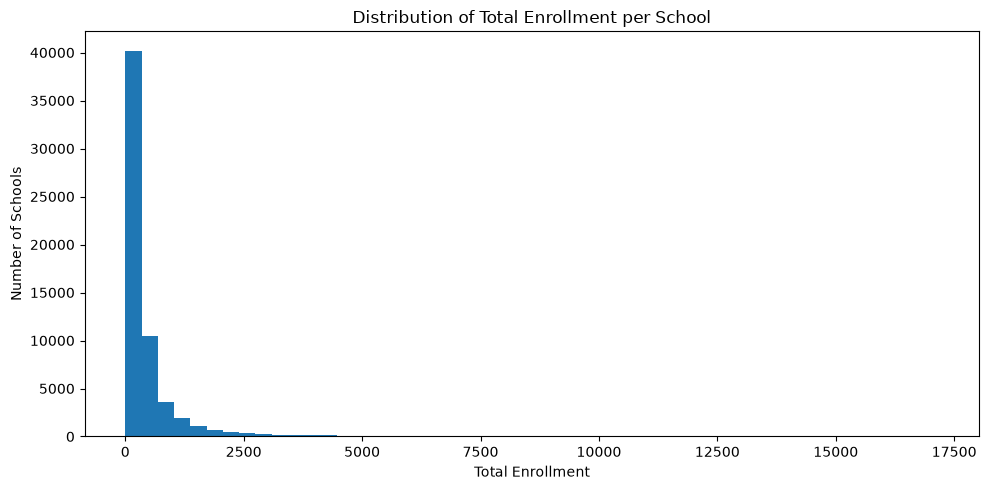

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(total_enrollment, bins=50)

plt.title("Distribution of Total Enrollment per School")
plt.xlabel("Total Enrollment")
plt.ylabel("Number of Schools")

plt.tight_layout()
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16236\3489886453.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(total_enrollment, vert=False)


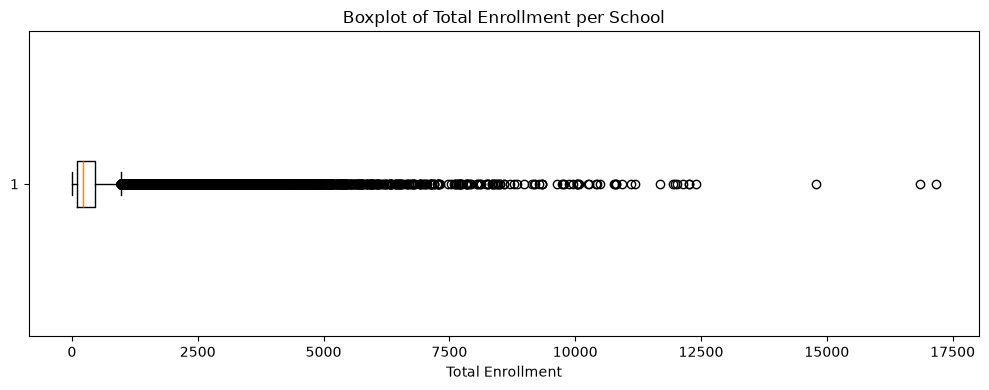

In [61]:
plt.figure(figsize=(10, 4))

plt.boxplot(total_enrollment, vert=False)

plt.title("Boxplot of Total Enrollment per School")
plt.xlabel("Total Enrollment")

plt.tight_layout()
plt.show()

In [64]:
# Outlier calculation using IQR method

# Calculate interquartile range
Q1 = total_enrollment.quantile(0.25)
Q3 = total_enrollment.quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 106.0
Q3: 452.0
IQR: 346.0
Lower Bound: -413.0
Upper Bound: 971.0


In [65]:
# Identify potential outliers
outliers = total_enrollment[
    (total_enrollment < lower_bound) |
    (total_enrollment > upper_bound)
]

print("Number of potential outliers:", len(outliers))
print("Percentage of schools:", (len(outliers) / len(df)) * 100)

Number of potential outliers: 6367
Percentage of schools: 10.58221284092609


In [66]:
# Display the 10 schools with the highest enrollment
top_enrollment_schools = (
    df[["BEIS School ID", "School Name", "Region",
        "Division", "Sector"]]
    .assign(Total_Enrollment=total_enrollment)
    .sort_values("Total_Enrollment", ascending=False)
    .head(10)
)

print(top_enrollment_schools.to_string(index=False))

 BEIS School ID                              School Name      Region            Division Sector  Total_Enrollment
         305330                Batasan Hills National HS         NCR         Quezon City Public             17167
         305424      Paranaque National High School Main         NCR      Paranaque City Public             16847
         304360                           Davao City NHS   Region XI          Davao City Public             14790
         304642 General Santos City National High School  Region XII General Santos City Public             12399
         302285              Tabaco National High School    Region V         Tabaco City Public             12260
         305413                        Rizal High School         NCR          Pasig City Public             12259
         301418            Antipolo National High School Region IV-A       Antipolo City Public             12138
         301219              Tanza National Trade School Region IV-A              Cavite

In [67]:
outlier_mask = total_enrollment > upper_bound

outliers_by_sector = (
    df.assign(
        Total_Enrollment=total_enrollment,
        Is_Outlier=outlier_mask
    )
    .groupby("Sector")
    .agg(
        Total_Schools=("BEIS School ID", "count"),
        Potential_Outliers=("Is_Outlier", "sum")
    )
)

outliers_by_sector["Outlier Percentage"] = (
    outliers_by_sector["Potential_Outliers"]
    / outliers_by_sector["Total_Schools"]
) * 100

print(outliers_by_sector)

          Total_Schools  Potential_Outliers  Outlier Percentage
Sector                                                         
PSO                  33                  11           33.333333
Private           12113                 888            7.330967
Public            47818                5446           11.389017
SUCsLUCs            203                  22           10.837438


### Initial Observations

1. The average school enrollment is approximately 450 learners, while the median is 211. The difference suggests a right-skewed distribution, where a relatively small number of schools with high enrollment raise the mean.

2. The middle 50% of schools have enrollment counts between 106 and 452 learners.

3. Using the IQR method, schools with enrollment above 971 were classified as potential high outliers. There are 6,367 such schools, representing approximately 10.58% of the dataset.

4. The highest recorded enrollment is 17,167 learners at Batasan Hills National High School in NCR.

5. The histogram and boxplot show a concentration of schools with relatively low enrollment and a long right tail of schools with substantially higher enrollment.

6. Potential outliers should be investigated rather than automatically removed because high enrollment may reflect the actual size of a school.

7. Potential high outliers are not evenly distributed across school sectors. Public schools have the highest number of potential outliers (5,446), while PSO has the highest proportion (33.33%). However, PSO has only 33 school records, so its percentage should be interpreted cautiously.

8. Private schools have the lowest proportion of potential outliers at 7.33%. These differences may reflect variations in school enrollment sizes across sectors and warrant further exploration.